# GLASS mock grid: QML vs NaMaster vs heracles, per-$\ell$ and in bandpowers

Makes every figure and table in `GlassTests/QML_GLASS_report.tex` from the grid results written by
`examples/qml_grid_pipeline.py` (`data/qml_grid_results/results_*.npz`, one per galaxy density and footprint).

- **Per-$\ell$**: the original analysis, one QML estimate per multipole ($2\le\ell\le2N_\mathrm{side}$).
- **Bandpowers**: $\Delta\ell=20$ bands from $\ell=10$, binned *before* inverting the QML Fisher matrix, as for TR1
  South. The same bands are used for NaMaster and heracles.
- heracles keeps the shot noise (`debias=False`), like QML ($F^{-1}y$) and NaMaster, so all three are compared with
  the signal + noise theory.
- GLASS builds its fields on the $N_\mathrm{side}=64$ HEALPix grid, so the simulated shear signal is smoothed by the
  pixel window. The theory signal is multiplied by $w_\ell^2$ (healpy's pixel window) before comparison; without it all
  three estimators sit up to ~50% below theory at the highest bands.

In [1]:
import os
import numpy as np
import healpy as hp
from scipy.stats import chi2 as chi2_dist
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

%matplotlib inline
plt.rcParams['text.usetex'] = False
sns.set(font_scale=1.1, rc={'text.usetex': False, 'figure.dpi': 110})

root_filepath = os.path.dirname(os.path.abspath(os.getcwd()))  # the notebook runs from GlassTests/
n_side = 64
results_dir = f'{root_filepath}/data/qml_grid_results'
fig_dir = f'{root_filepath}/GlassTests/figures'
os.makedirs(fig_dir, exist_ok=True)

n_arcmin2_values = [1, 10, 20]
footprints = [(55, 125), (65, 115), (75, 105)]
BLUE, ORANGE, GREEN, PINK, INK = '#2a78d6', '#eb6834', '#1baf7a', '#e8579b', '#52514e'

# Pixel window of the simulated fields, applied to the theory signal (not to the noise)
pixwin2 = hp.pixwin(n_side, lmax=3 * n_side - 1) ** 2

results = {}
for n in n_arcmin2_values:
    cl_signal = np.loadtxt(f'{root_filepath}/data/theory_cl_vals/TheorySpectra_N{n_side}_glass_ngal{n:g}.dat')
    for lo, hi in footprints:
        with np.load(f'{results_dir}/results_ngal{n:g}_fp{lo}_{hi}.npz') as npz:
            r = {key: npz[key] for key in npz.files}
        noise = float(r['cl_noise'])
        r['cl_EE_theory'] = cl_signal[r['ells']] * pixwin2[r['ells']] + noise
        r['cl_EE_theory_bp'] = np.array([np.mean(cl_signal[a:b] * pixwin2[a:b])
                                         for a, b in zip(r['ell_bp_ini'], r['ell_bp_end'])]) + noise
        results[(n, (lo, hi))] = r
print(f'loaded {len(results)} combos; per-ell range l = {results[(1, footprints[0])]["ells"][[0, -1]]}, '
      f'bands {list(zip(results[(1, footprints[0])]["ell_bp_ini"], results[(1, footprints[0])]["ell_bp_end"] - 1))}')


def grid_axes(sharey=False):
    fig, axes = plt.subplots(len(n_arcmin2_values), len(footprints), figsize=(13, 9.6), sharex=True, sharey=sharey,
                             squeeze=False)
    for row, n in enumerate(n_arcmin2_values):
        for col, (lo, hi) in enumerate(footprints):
            ax = axes[row, col]
            if row == 0:
                f_sky = 100 * float(results[(n, (lo, hi))]['f_sky'])
                ax.set_title(f'footprint ({lo}, {hi})°, $f_{{\\rm sky}}$ = {f_sky:.0f}%', fontsize=11)
            if row == len(n_arcmin2_values) - 1:
                ax.set_xlabel(r'$\ell$')
    return fig, axes


def save(fig, name):
    fig.savefig(f'{fig_dir}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

loaded 9 combos; per-ell range l = [  2 128], bands [(np.int64(10), np.int64(29)), (np.int64(30), np.int64(49)), (np.int64(50), np.int64(69)), (np.int64(70), np.int64(89)), (np.int64(90), np.int64(109)), (np.int64(110), np.int64(129)), (np.int64(130), np.int64(149)), (np.int64(150), np.int64(169)), (np.int64(170), np.int64(191))]


## Footprint masks

footprint (55, 125) deg: f_sky = 15.26 %
footprint (65, 115) deg: f_sky = 30.83 %
footprint (75, 105) deg: f_sky = 55.55 %


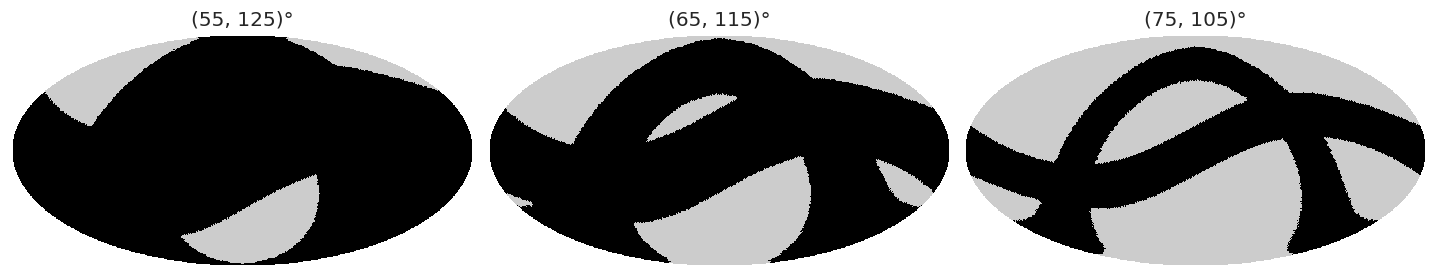

In [2]:
fig = plt.figure(figsize=(13, 3.6))
for i, (lo, hi) in enumerate(footprints):
    mask = hp.read_map(f'{root_filepath}/data/masks/SkyMask_glass_N{n_side}_fp{lo}_{hi}.fits') > 0
    print(f'footprint ({lo}, {hi}) deg: f_sky = {100 * mask.mean():.2f} %')
    hp.mollview(mask, cmap='nipy_spectral', cbar=False, title=f'({lo}, {hi})°', sub=(1, len(footprints), i + 1), fig=fig)
save(fig, 'masks_N64')

## Per-$\ell$ results

Unbinned estimates for $2\le\ell\le2N_\mathrm{side}$. Theory lines: EE signal (with pixel window) + noise, BB noise only.

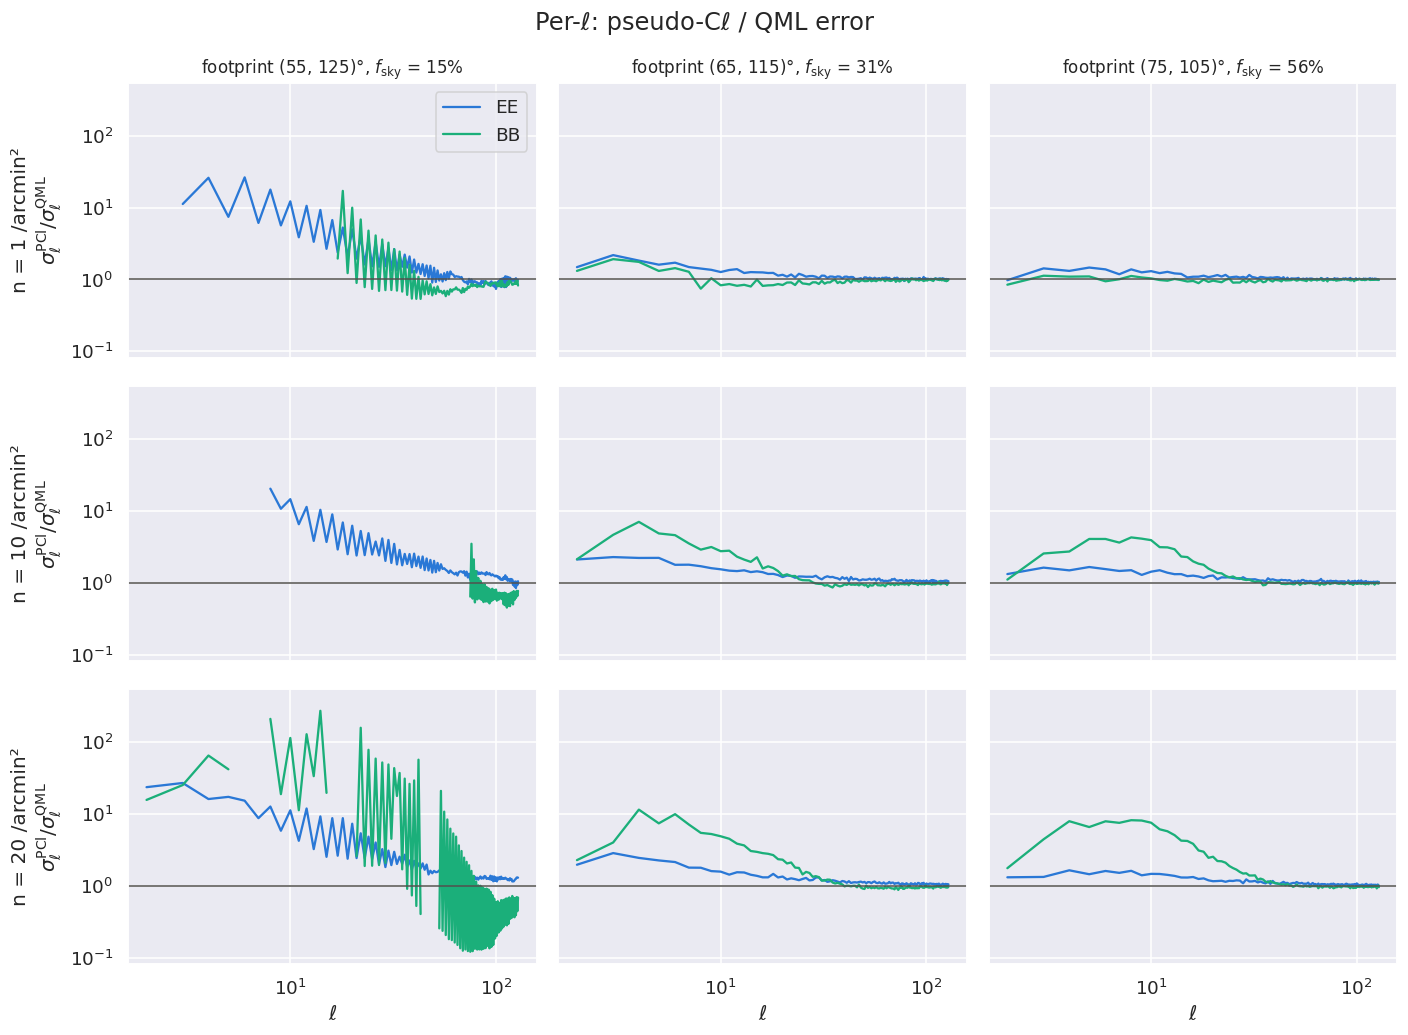

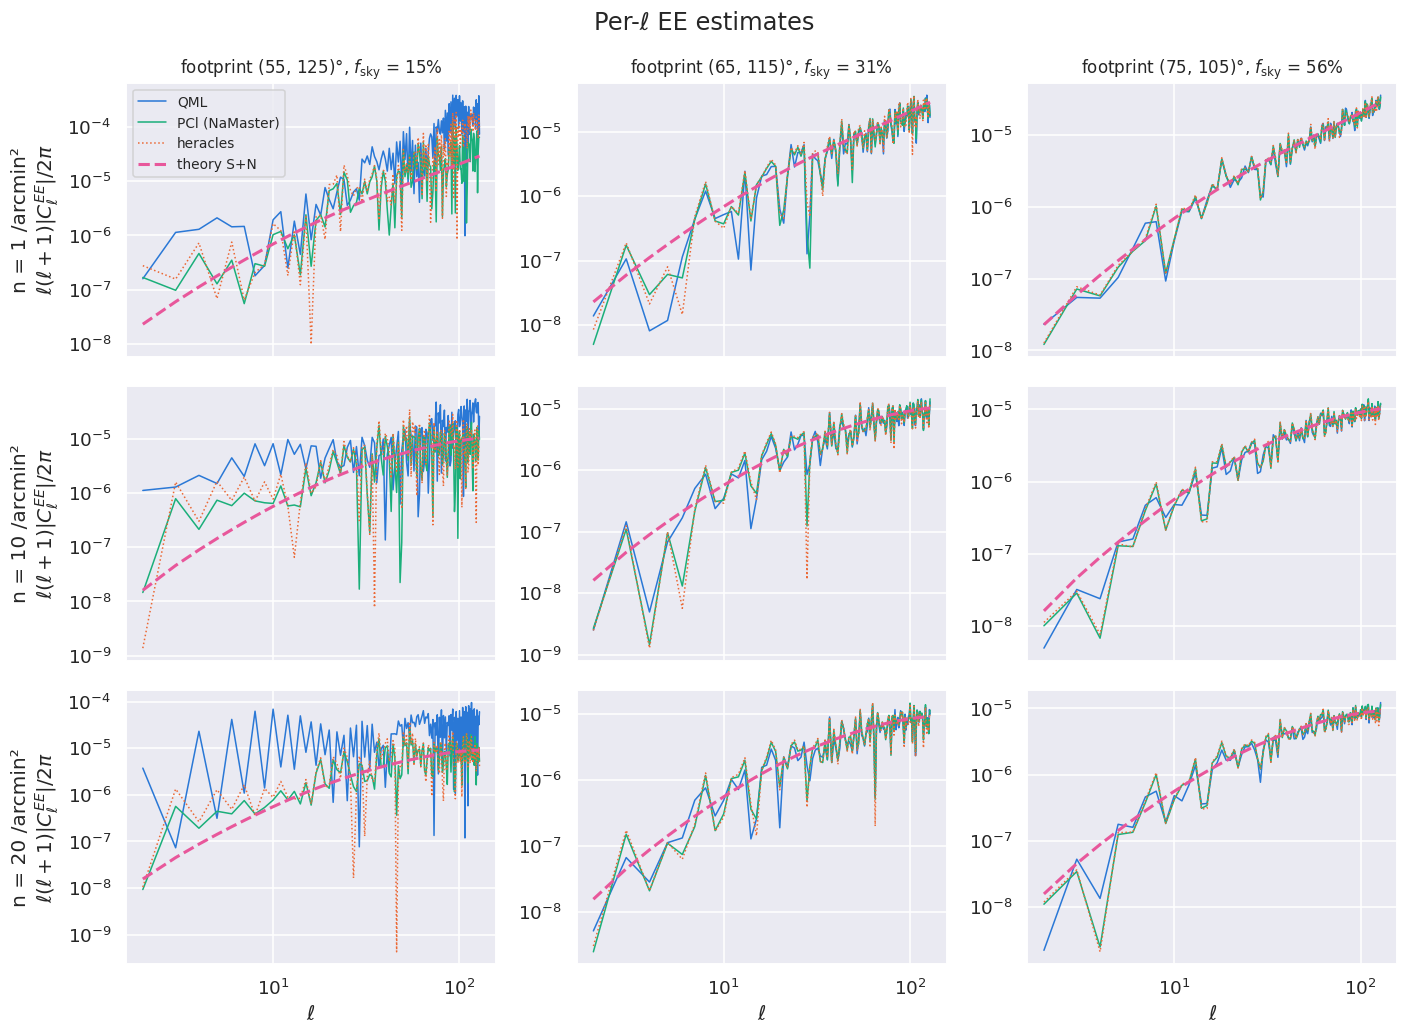

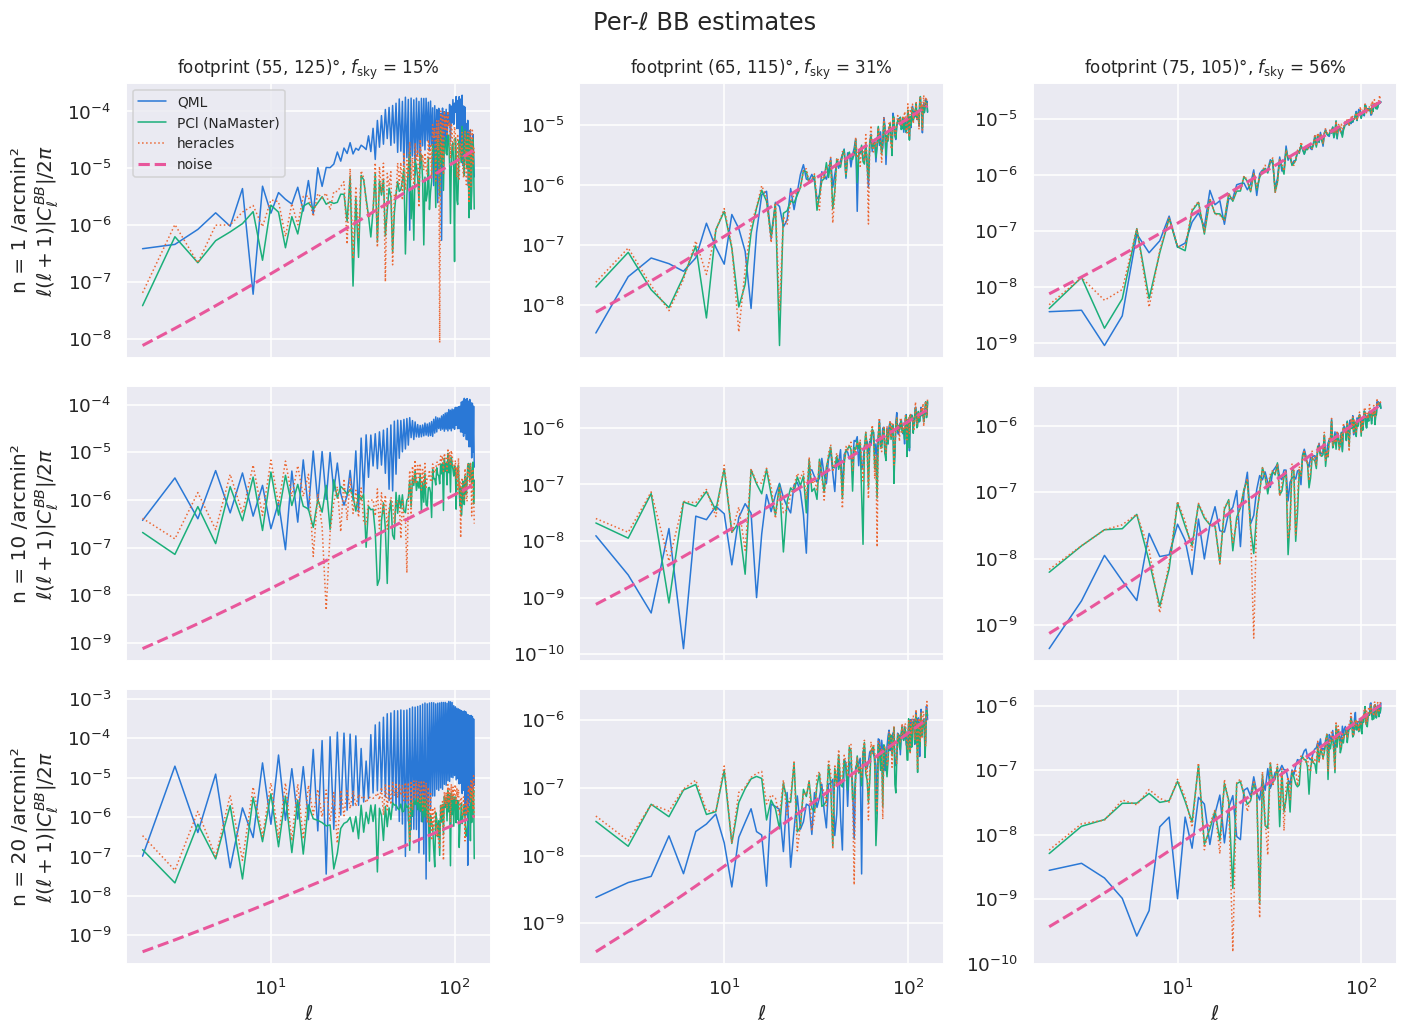

In [3]:
fig, axes = grid_axes(sharey=True)
for (n, fp), r in results.items():
    ax = axes[n_arcmin2_values.index(n), footprints.index(fp)]
    ax.loglog(r['ells'], r['sigma_ratio_EE'], color=BLUE, lw=1.5, label='EE')
    ax.loglog(r['ells'], r['sigma_ratio_BB'], color=GREEN, lw=1.5, label='BB')
    ax.axhline(1, color=INK, lw=1)
for row, n in enumerate(n_arcmin2_values):
    axes[row, 0].set_ylabel(f'n = {n:g} /arcmin²\n' + r'$\sigma_\ell^{\rm PCl}/\sigma_\ell^{\rm QML}$')
axes[0, 0].legend()
fig.suptitle('Per-ℓ: pseudo-Cℓ / QML error')
fig.tight_layout()
save(fig, 'sigma_ratio_N64')

for spec in ['EE', 'BB']:
    fig, axes = grid_axes()
    for (n, fp), r in results.items():
        ax = axes[n_arcmin2_values.index(n), footprints.index(fp)]
        ells = r['ells']
        f = ells * (ells + 1) / (2 * np.pi)
        ax.loglog(ells, f * np.abs(r[f'cl_{spec}_QML']), color=BLUE, lw=1, label='QML')
        ax.loglog(ells, f * np.abs(r[f'cl_{spec}_PCl']), color=GREEN, lw=1, label='PCl (NaMaster)')
        ax.loglog(ells, f * np.abs(r[f'cl_{spec}_heracles']), color=ORANGE, lw=1, ls=':', label='heracles')
        theory = r['cl_EE_theory'] if spec == 'EE' else np.full(len(ells), float(r['cl_noise']))
        ax.loglog(ells, f * theory, color=PINK, lw=2, ls='--', label='theory S+N' if spec == 'EE' else 'noise')
    for row, n in enumerate(n_arcmin2_values):
        axes[row, 0].set_ylabel(f'n = {n:g} /arcmin²\n' + rf'$\ell(\ell+1)|C_\ell^{{{spec}}}|/2\pi$')
    axes[0, 0].legend(fontsize=9)
    fig.suptitle(f'Per-ℓ {spec} estimates')
    fig.tight_layout()
    save(fig, f'{spec}_N64')

In [4]:
# Per-ell B-mode null test: mean QML |C_l^BB| / noise, at l < 30 and over every l
print(f'{"n":>4} {"footprint":>11} {"BB/noise (l<30)":>16} {"BB/noise (all l)":>17}')
per_ell_ratio = {}
for (n, (lo, hi)), r in results.items():
    ratio = np.abs(r['cl_BB_QML']) / float(r['cl_noise'])
    per_ell_ratio[(n, (lo, hi))] = ratio.mean()
    print(f'{n:>4g} {f"({lo},{hi})":>11} {ratio[r["ells"] < 30].mean():>16.2f} {ratio.mean():>17.2f}')

   n   footprint  BB/noise (l<30)  BB/noise (all l)
   1    (55,125)            22.49             14.87
   1    (65,115)             1.11              0.98
   1    (75,105)             0.81              0.93
  10    (55,125)           212.58             89.95
  10    (65,115)             1.90              1.23
  10    (75,105)             1.34              1.05
  20    (55,125)          2383.41           1197.65
  20    (65,115)             2.76              1.41
  20    (75,105)             1.64              1.15


## Bandpowers ($\Delta\ell=20$)

Errors: QML from its binned Fisher matrix, NaMaster from its Gaussian covariance on the same bands. The theory is
binned the same way (EE signal + noise; BB noise).

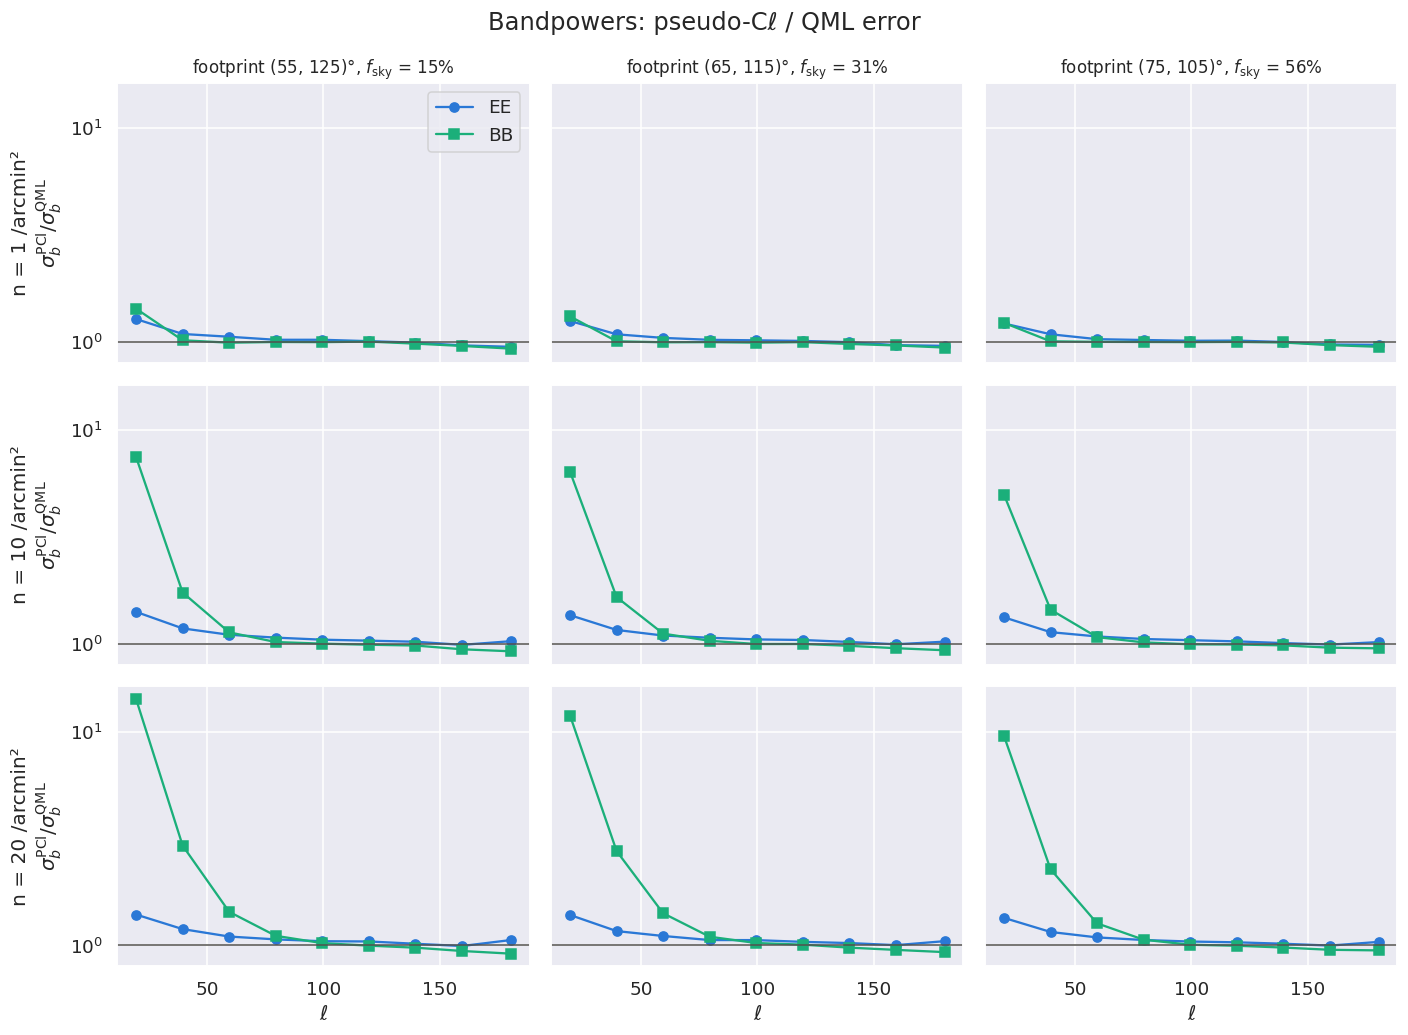

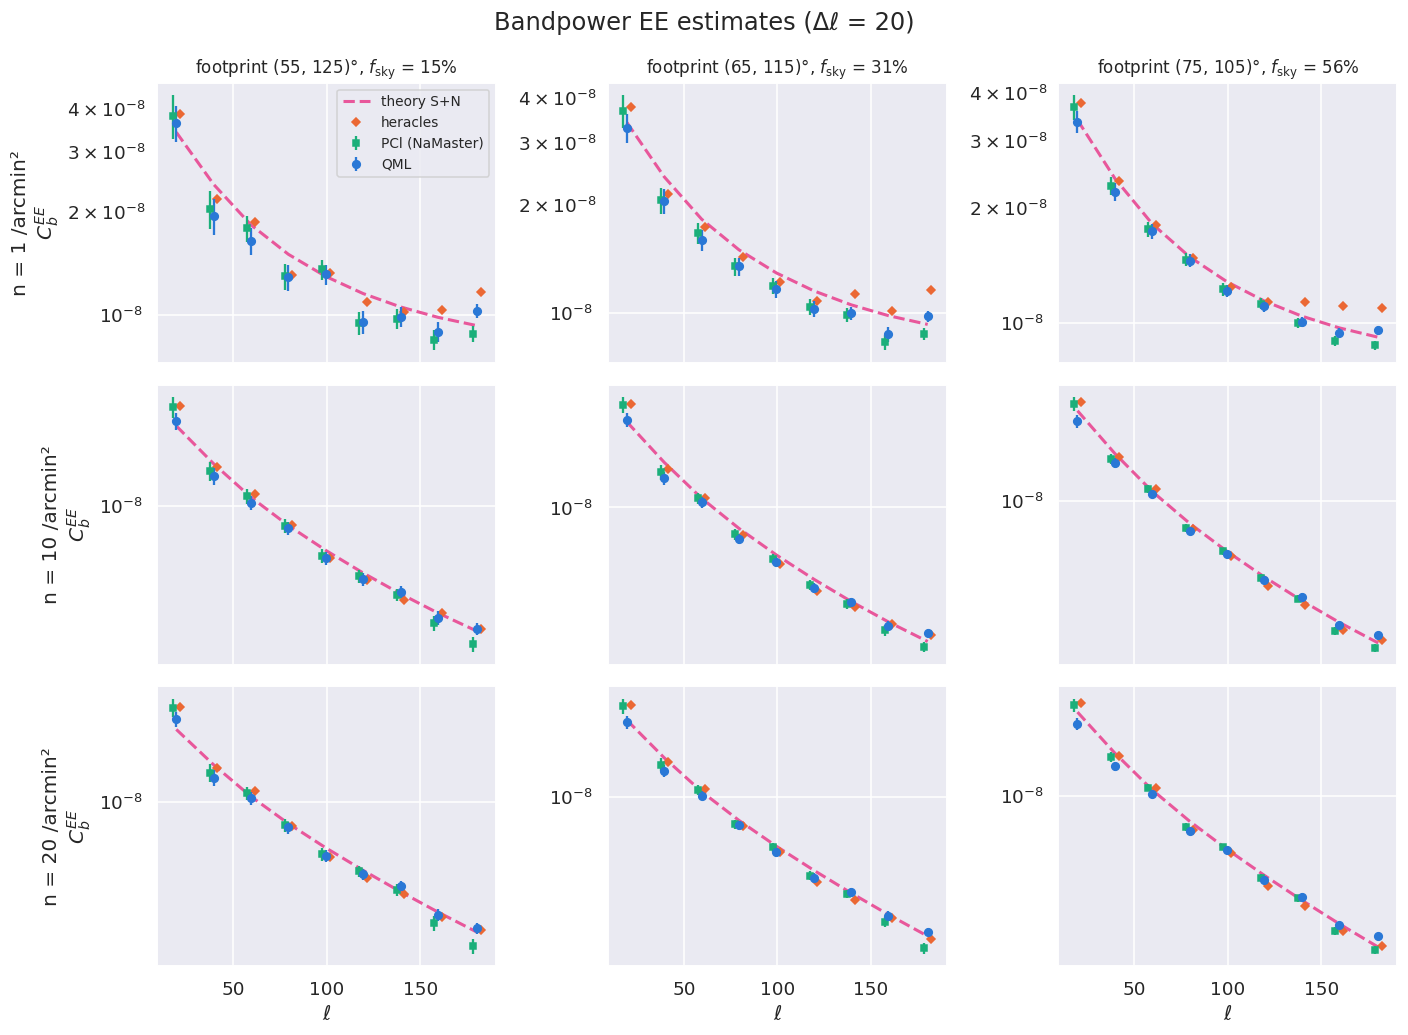

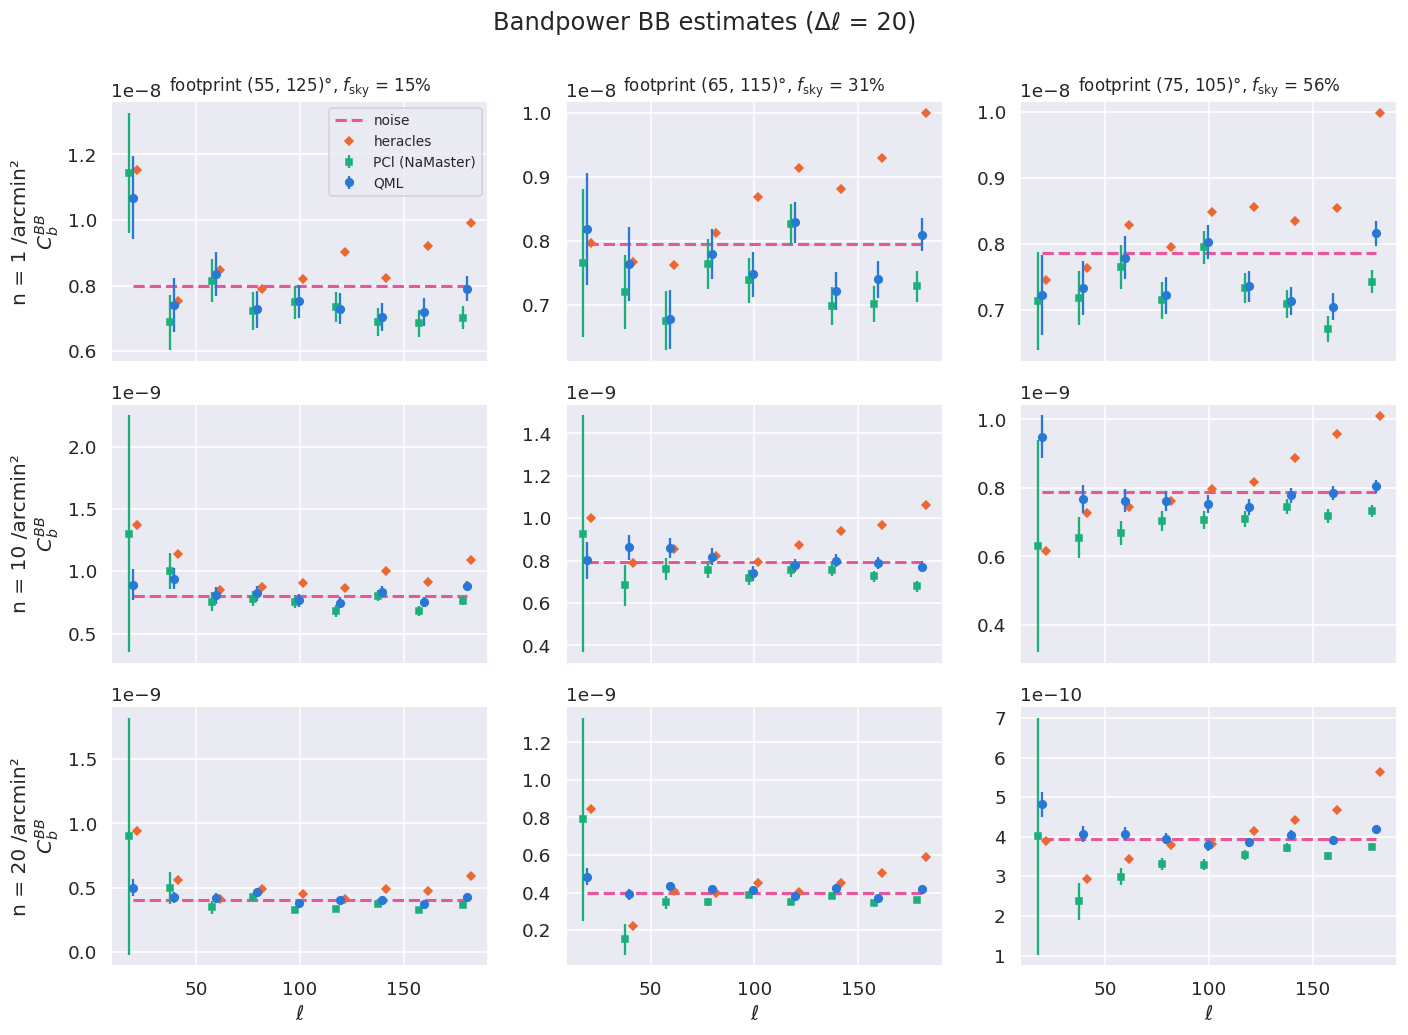

In [5]:
fig, axes = grid_axes(sharey=True)
for (n, fp), r in results.items():
    ax = axes[n_arcmin2_values.index(n), footprints.index(fp)]
    for spec, color, marker in [('EE', BLUE, 'o'), ('BB', GREEN, 's')]:
        ratio = np.sqrt(np.diag(r[f'cov_{spec}_{spec}_PCl_bp']) / np.diag(r[f'cov_{spec}_{spec}_QML_bp']))
        ax.semilogy(r['ell_bp'], ratio, marker=marker, color=color, lw=1.5, label=spec)
    ax.axhline(1, color=INK, lw=1)
for row, n in enumerate(n_arcmin2_values):
    axes[row, 0].set_ylabel(f'n = {n:g} /arcmin²\n' + r'$\sigma_b^{\rm PCl}/\sigma_b^{\rm QML}$')
axes[0, 0].legend()
fig.suptitle('Bandpowers: pseudo-Cℓ / QML error')
fig.tight_layout()
save(fig, 'sigma_ratio_bp_N64')

for spec in ['EE', 'BB']:
    fig, axes = grid_axes()
    for (n, fp), r in results.items():
        ax = axes[n_arcmin2_values.index(n), footprints.index(fp)]
        ell_bp = r['ell_bp']
        theory = r['cl_EE_theory_bp'] if spec == 'EE' else np.full(len(ell_bp), float(r['cl_noise']))
        ax.plot(ell_bp, theory, color=PINK, lw=2, ls='--', label='theory S+N' if spec == 'EE' else 'noise')
        ax.errorbar(ell_bp - 2, r[f'cl_{spec}_PCl_bp'], np.sqrt(np.diag(r[f'cov_{spec}_{spec}_PCl_bp'])), fmt='s',
                    color=GREEN, ms=4, label='PCl (NaMaster)')
        ax.plot(ell_bp + 2, r[f'cl_{spec}_heracles_bp'], 'D', color=ORANGE, ms=4, label='heracles')
        ax.errorbar(ell_bp, r[f'cl_{spec}_QML_bp'], np.sqrt(np.diag(r[f'cov_{spec}_{spec}_QML_bp'])), fmt='o',
                    color=BLUE, ms=5, label='QML')
        if spec == 'EE':
            ax.set_yscale('log')
    for row, n in enumerate(n_arcmin2_values):
        axes[row, 0].set_ylabel(f'n = {n:g} /arcmin²\n' + rf'$C_b^{{{spec}}}$')
    axes[0, 0].legend(fontsize=9)
    fig.suptitle(f'Bandpower {spec} estimates (Δℓ = 20)')
    fig.tight_layout()
    save(fig, f'{spec}_bp_N64')

In [6]:
# Bandpower tests, for the QML estimates and their binned-Fisher covariance:
#   BB against pure noise (null test) and EE against the signal + noise theory, chi^2 and its PTE
def chi2_pte(d, cov):
    x2 = d @ np.linalg.solve(cov, d)
    return x2, chi2_dist.sf(x2, len(d))


bp_tests = {}
print(f'{"n":>4} {"footprint":>11} {"|BB|/noise":>11} {"BB chi2":>8} {"BB PTE":>7} {"EE chi2":>8} {"EE PTE":>7}  (bands: {len(results[(1, footprints[0])]["ell_bp"])})')
for (n, (lo, hi)), r in results.items():
    noise = float(r['cl_noise'])
    x2B, pB = chi2_pte(r['cl_BB_QML_bp'] - noise, r['cov_BB_BB_QML_bp'])
    x2E, pE = chi2_pte(r['cl_EE_QML_bp'] - r['cl_EE_theory_bp'], r['cov_EE_EE_QML_bp'])
    bp_tests[(n, (lo, hi))] = (np.mean(np.abs(r['cl_BB_QML_bp'])) / noise, pB)
    print(f'{n:>4g} {f"({lo},{hi})":>11} {bp_tests[(n, (lo, hi))][0]:>11.2f} {x2B:>8.1f} {pB:>7.2f} {x2E:>8.1f} {pE:>7.2f}')

   n   footprint  |BB|/noise  BB chi2  BB PTE  EE chi2  EE PTE  (bands: 9)
   1    (55,125)        0.98     20.3    0.02     25.1    0.00
   1    (65,115)        0.96     20.4    0.02     38.3    0.00
   1    (75,105)        0.95     45.0    0.00     12.3    0.19
  10    (55,125)        1.03     11.2    0.26      6.9    0.65
  10    (65,115)        1.01      7.4    0.59     23.6    0.01
  10    (75,105)        1.00     14.9    0.09     21.1    0.01
  20    (55,125)        1.05     12.0    0.21      9.2    0.42
  20    (65,115)        1.04     16.2    0.06     14.4    0.11
  20    (75,105)        1.04     19.3    0.02     37.4    0.00


## Summary: the grid in the sky-fraction / density plane

Clean B-mode null test: per-$\ell$ mean $|C_\ell^{BB}|$/noise below 2 (left); bandpower $\chi^2$ PTE against pure
noise above 0.01 (right).

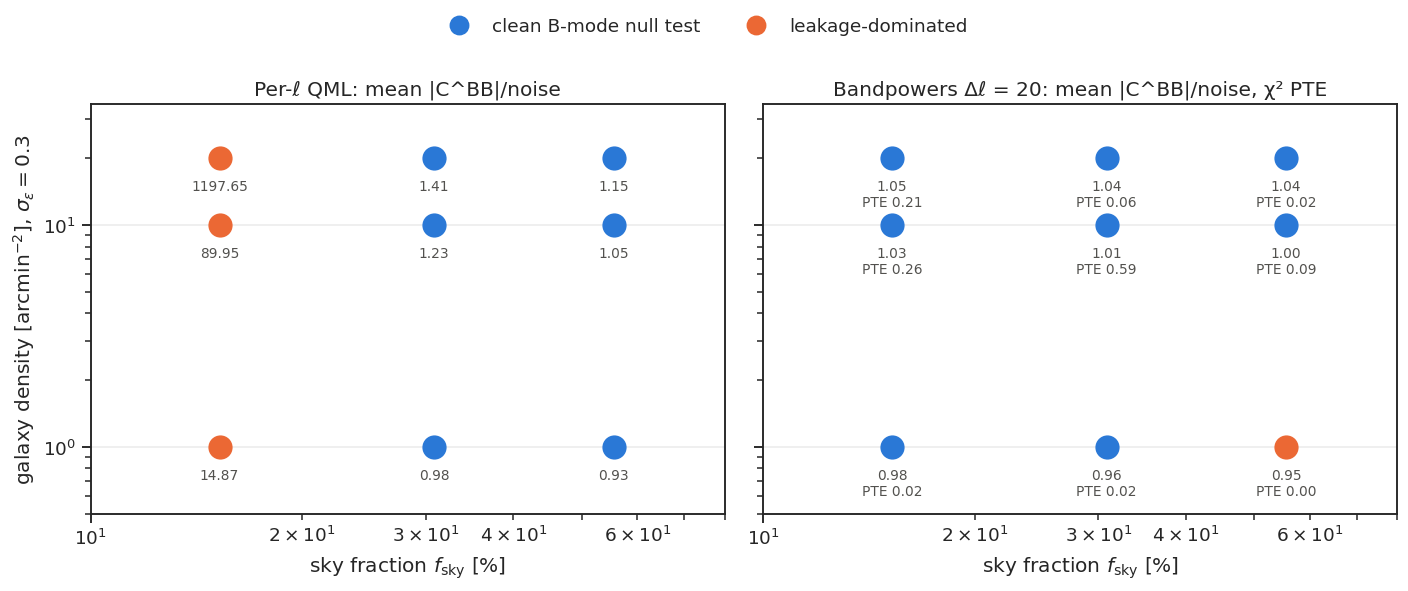

In [7]:
with sns.axes_style('ticks'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
    for ax, panel in zip(axes, ['per-ell', 'bandpower']):
        for (n, fp), r in results.items():
            f_sky = 100 * float(r['f_sky'])
            if panel == 'per-ell':
                value = per_ell_ratio[(n, fp)]
                clean, label = value < 2, f'{value:.2f}'
            else:
                value, pte = bp_tests[(n, fp)]
                clean, label = pte > 0.01, f'{value:.2f}\nPTE {pte:.2f}'
            ax.scatter(f_sky, n, s=220, color=BLUE if clean else ORANGE, zorder=3)
            ax.annotate(label, (f_sky, n), xytext=(0, -14), textcoords='offset points', ha='center', va='top',
                        fontsize=9, color=INK)
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xlim(10, 80); ax.set_ylim(0.5, 35)
        ax.set_xlabel(r'sky fraction $f_{\rm sky}$ [%]')
        ax.grid(alpha=0.4)
    axes[0].set_ylabel(r'galaxy density [arcmin$^{-2}$], $\sigma_\epsilon = 0.3$')
    axes[0].set_title('Per-ℓ QML: mean |C^BB|/noise')
    axes[1].set_title('Bandpowers Δℓ = 20: mean |C^BB|/noise, χ² PTE')
    handles = [Line2D([], [], marker='o', ls='', ms=12, color=BLUE, label='clean B-mode null test'),
               Line2D([], [], marker='o', ls='', ms=12, color=ORANGE, label='leakage-dominated')]
    fig.legend(handles=handles, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.05), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    save(fig, 'null_test_plane_N64')